# Mandatory assignment 3

**GitHub repository:** https://github.com/pl0gen/assignment3

## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

In [2]:
import pandas as pd
import numpy as np #Library

#1. Loading the csv-file. Print columns and their number of non-missing values
file = "SCF_10pct.csv"
df = pd.read_csv(file)

print("1. Non-missing values per column:")
print(df.notna().sum())  #Printing the columns contained in the DataFrame and their numbers of non-missing values



#2. Drop all observations that have missing values. Reporting how many dropped and how many remain. 
df1  = df.dropna()
n_before0 = len(df)
n_after1 = len(df1)
change1 = n_before0 - n_after1
print(f"2.1 In total we dropped: {change1} rows ")

for columns in df1: #Looping over the columns in the DataFrame. 
    n_before = len(df) 
    df1 = df.dropna(subset=[columns])
    print(f"{columns}: dropped {n_before - len(df1)}, remaining: {len(df1)}")




#3 Keep observations
df2 = df1[(df1["age"] >= 25) & (df1["age"] <= 89)]
n_before1 = len(df1)
n_after2 = len(df2)
change2 = n_before1-n_after2
print(f"3. In total we dropped: {change2} rows after age restriction ")




#4 Indicator columsn

direct = []
for var in df2["stocks"]: 
    if var > 0: 
        direct.append(1)
    else: 
        direct.append(0)
df2["direct"] = direct


indirect = []
for var in df2["equity"]: 
    if var > 0: 
        indirect.append(1)
    else: 
        indirect.append(0)
df2["indirect"] = indirect


df2["overall"] = df2["direct"]| df2["indirect"]
df2



1. Non-missing values per column:
id        5808
year      5808
age       5808
educ      5792
stocks    5790
equity    5792
dtype: int64
2.1 In total we dropped: 50 rows 
id: dropped 0, remaining: 5808
year: dropped 0, remaining: 5808
age: dropped 0, remaining: 5808
educ: dropped 16, remaining: 5792
stocks: dropped 18, remaining: 5790
equity: dropped 16, remaining: 5792
3. In total we dropped: 328 rows after age restriction 


,id,year,age,educ,stocks,equity,direct,indirect,overall
0,0,1989,35,2.0,0.0,0.0,0,0,0
1,1,1989,33,2.0,0.0,0.0,0,0,0
2,2,1989,62,1.0,0.0,0.0,0,0,0
4,4,1989,70,1.0,0.0,0.0,0,0,0
5,5,1989,50,1.0,0.0,0.0,0,0,0
...,...,...,...,...,...,...,...,...,...
5802,5802,2022,77,3.0,0.0,0.0,0,0,0
5804,5804,2022,33,3.0,0.0,0.0,0,0,0
5805,5805,2022,81,2.0,100000.0,100000.0,1,1,1
5806,5806,2022,58,3.0,40000.0,1212000.0,1,1,1


***
## Part 2 — Participation rates

You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

In [3]:
# 1. Function

def participation_rate(indicator):
    count = 0
    for n in indicator:
        count = count + n #0s add nothing, so count = number of 1s
    percentage = (count / len(indicator))*100 # Number of 1s divided by the total length of the Pandas series.  

    return percentage

# 2 Function
print(f" The direct participiation rate is: {participation_rate(df2["direct"]):.1f}%") # Our function already multiplies by 100, so we use :.1f and add % ourselves. 
# Using :.1% here would multiply by 100 again (16.9 to 1692.9%).


print(f" The overall-participiation rate is: {participation_rate(df2["overall"]):.1f}%")


# 3. Pandas inbuilt
print(f" The direct participation rate with inbuilt function is: {df2["direct"].mean():.1%}")
print(f" The overall participation rate with inbuilt function is: {df2["overall"].mean():.1%}")

#The results of out function and the built in function is the same. 


#It is clear that the inbuilt function is faster in higher volumes. 
%timeit participation_rate(df2["direct"])
%timeit df2["direct"].mean()



 The direct participiation rate is: 16.9%
 The overall-participiation rate is: 49.5%
 The direct participation rate with inbuilt function is: 16.9%
 The overall participation rate with inbuilt function is: 49.5%
124 μs ± 292 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)
8.78 μs ± 255 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

direct     16.8 pp
overall    25.1 pp
dtype: str


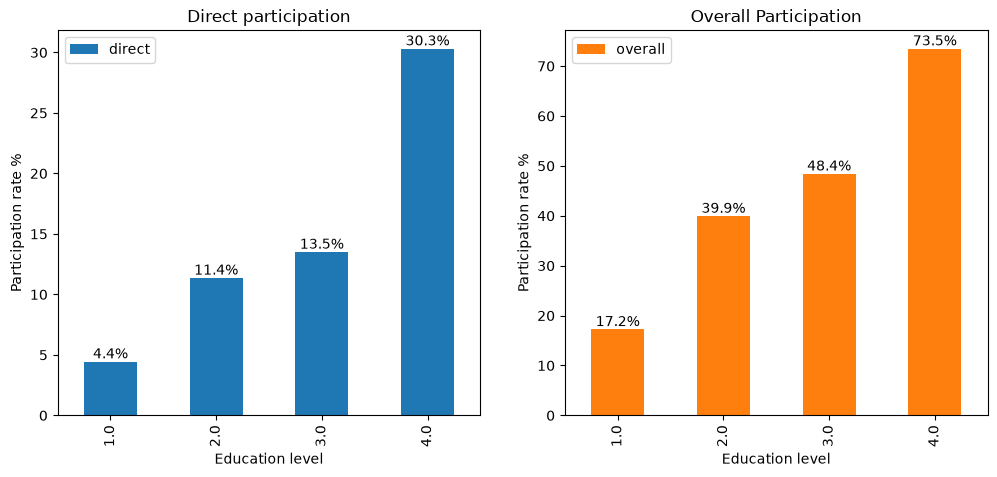

In [34]:

#1. Participation rate by education
group = df2.groupby("educ")[["direct","overall"]] #Using groupby to finding the mean of direct and overall, to find the participation per index which is the education level

#2. Representing the participiation rate
group.mean().map(lambda x: f"{x:.1%}") #The way of representing in percentage. .map() runs the function on every cell, and passes the cell into the lambda as x, lambda converts x to a percentage

#3.Creating figure with two subplots. 
educ = df2.groupby("educ")[["direct","overall"]].mean()*100
axes = educ.plot.bar(subplots=True,layout=(1,2),figsize=(12,5), title = ["Direct participation", "Overall Participation"], ylabel="Participation rate %", xlabel="Education level")


for ax in axes.flat:                                   # loop over both subplots
    ax.bar_label(ax.containers[0], fmt="%.1f%%")        

#4. Desbrice the education pattern

# Higher education is associated with higher participation, both in direct stock
# ownership and in overall equity ownership. The largest jump is between "some college"
# and "bachelor's degree or higher": direct participation rises from 13.5% to 30.3%
# (+16.8 pp) and overall participation from 48.4% to 73.5% (+25.1 pp).

diff = educ.iloc[3] - educ.iloc[2]
print(diff.map(lambda x: f"{x:.1f} pp"))

Education 1: direct 4.4%, overall 17.2%
Education 2: direct 11.4%, overall 39.9%
Education 3: direct 13.5%, overall 48.4%
Education 4: direct 30.3%, overall 73.5%


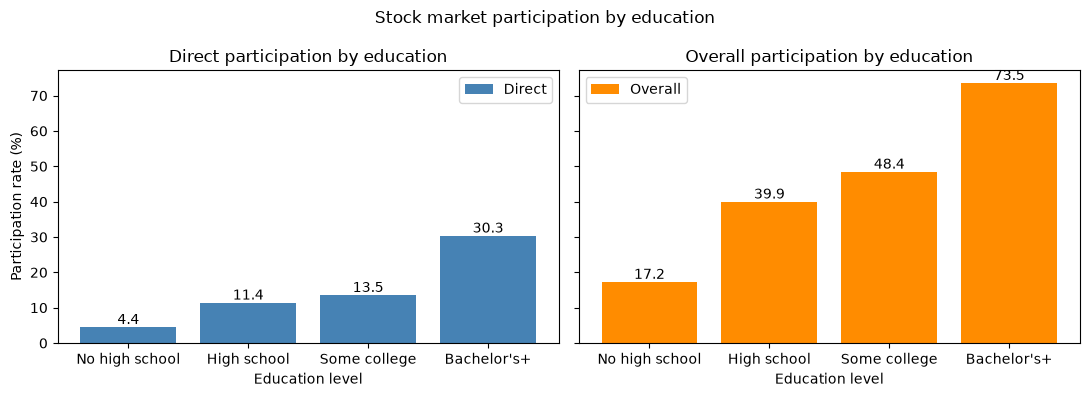

In [35]:
import matplotlib.pyplot as plt


# 1,2. Display the result
direct_rates = []
overall_rates = []

for e in [1, 2, 3, 4]: #Using loops instead
    d = participation_rate(df2["direct"][df2["educ"] == e])
    o = participation_rate(df2["overall"][df2["educ"] == e])
    direct_rates.append(d)
    overall_rates.append(o)
    print(f"Education {e}: direct {d:.1f}%, overall {o:.1f}%")


# 3.
labels = ["No high school", "High school", "Some college", "Bachelor's+"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True) # sharey makes the y-axis similar for both subplots

# Left subplot: direct participation
bars = axes[0].bar(labels, direct_rates, color="steelblue", label="Direct")
axes[0].bar_label(bars, fmt="%.1f")
axes[0].set_title("Direct participation by education")
axes[0].set_xlabel("Education level")
axes[0].set_ylabel("Participation rate (%)")
axes[0].legend()

# Right subplot: overall participation
bars = axes[1].bar(labels, overall_rates, color="darkorange", label="Overall")
axes[1].bar_label(bars, fmt="%.1f")
axes[1].set_title("Overall participation by education")
axes[1].set_xlabel("Education level")
axes[1].legend()

fig.suptitle("Stock market participation by education")
plt.tight_layout()
plt.show()


***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

Direct change: 3.4 pp
Overall change: 22.7 pp


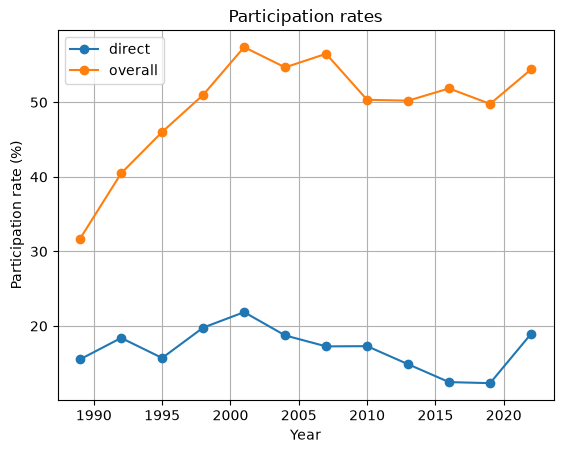

In [ ]:
#1. Using groupby to find the participation rate for direct and overall participation
group_years = df2.groupby("year")[["direct","overall"]].mean()*100#Easier way to structure the data
group_years.mean().map(lambda x: f"{x:.1%}") #The way of representing in percentage. .map() runs the function on every cell, and passes the cell into the lambda as x, lambda converts x to a percentage

#2. Create a line plot showing both participation over time in a single figure
group_years.plot(marker="o", title="Participation rates",ylabel="Participation rate (%)", xlabel="Year", grid=True, legend=True)

#3. The changes in percentage points
print(f"Direct change: {group_years.loc[2022, "direct"]-group_years.loc[1989,"direct"]:.1f} pp")
print(f"Overall change: {group_years.loc[2022, "overall"]-group_years.loc[1989, "overall"]:.1f} pp") 

#4. Main pattern. 
# Participation rose through the 1990s, then peaked during the dot-com boom in 2001, then fell after both the dot-com bubble popped and the 2008 financial crisis.
#After 2001, direct participation fell more than overall participation. Probably because households shiftet from individual stocks to less risky investmens . 



1989: direct 15.5%, overall 31.7%
1992: direct 18.4%, overall 40.5%
1995: direct 15.7%, overall 46.0%
1998: direct 19.8%, overall 51.0%
2001: direct 21.9%, overall 57.4%
2004: direct 18.7%, overall 54.7%
2007: direct 17.3%, overall 56.5%
2010: direct 17.3%, overall 50.3%
2013: direct 14.9%, overall 50.2%
2016: direct 12.5%, overall 51.9%
2019: direct 12.3%, overall 49.8%
2022: direct 18.9%, overall 54.4%


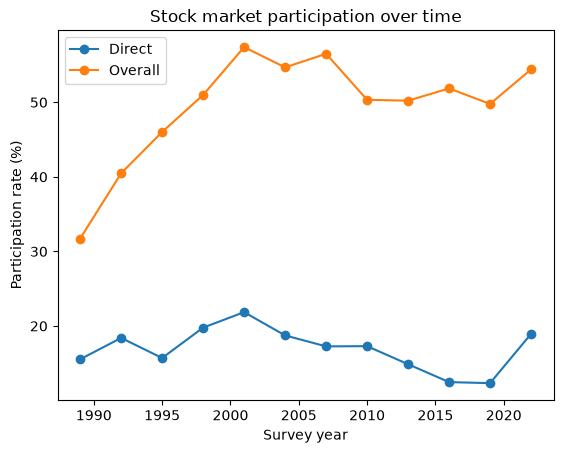

Direct change: 3.4 pp
Overall change: 22.7 pp


In [6]:
years = sorted(df2["year"].unique())   # 1989, 1992, ..., 2022

direct_by_year = []
overall_by_year = []


for y in years:
    d = participation_rate(df2["direct"][df2["year"] == y])
    o = participation_rate(df2["overall"][df2["year"] == y])
    direct_by_year.append(d)
    overall_by_year.append(o)
    print(f"{y}: direct {d:.1f}%, overall {o:.1f}%")


plt.plot(years, direct_by_year, marker="o", label="Direct")
plt.plot(years, overall_by_year, marker="o", label="Overall")
plt.title("Stock market participation over time")
plt.xlabel("Survey year")
plt.ylabel("Participation rate (%)")
plt.legend()
plt.show()

# 3. Change from 1989 to 2022 (first and last entries), in percentage points
print(f"Direct change: {direct_by_year[-1] - direct_by_year[0]:.1f} pp")
print(f"Overall change: {overall_by_year[-1] - overall_by_year[0]:.1f} pp")

***
## AI-use statement

Students must describe their own use of AI here, or state that they did not use it.

I used AI to

Where i used AI: 

1. Write a loop to iterate over subplots to give each bar a label with percentage. 
2. 